# Fine-Grained Image Difference Upgrade: DiffSpot End-to-End Evaluation

This notebook evaluates a lean, evidence-first screenshot comparison path on the **complete 4,400-pair DiffSpot test split**. The data contains 3,900 controlled, fine-grained changed pairs and 500 no-change controls. Each pair has a target element box, but **no pixel-level change mask**.

The earlier LEVIR-CD/SYSU-CD report showed that the full multimodal pipeline scored below the simple residual baseline on both five-pair slices (F1 0.108 vs 0.374 on LEVIR-CD; 0.234 vs 0.406 on SYSU-CD). Those results were pixel-mask scores from a tiny remote-sensing sample and are not directly comparable to the box-grounded benchmark below. They do show that registration, model fusion, and thresholds need measured evidence before inclusion.

## Design decisions from the problem statement

1. Keep the two source screenshots at native size and compare their pixels directly. The benchmark uses the same 1280×800 viewport and filters examples so visible residuals are inside the changed element. A geometric warp can smear, attenuate, or erase the subtle CSS changes under test.
2. Use the residual only to propose and localize changed pixels. Emit a location, pixel evidence, and an explicit “semantic type not inferred” status; never let a VLM invent a mask.
3. Calibrate a single residual threshold on a deterministic 20% calibration split, then report all metrics on the disjoint 80% holdout. The threshold is selected using pair-level F1 only.
4. Compare against per-image Otsu and a fixed-threshold residual. No pixel F1/IoU is computed because the target boxes are element annotations, not segmentation masks.

## Component selection

| Component | Decision for this benchmark | Reason |
|---|---|---|
| Native-resolution RGB residual + threshold | Core | Directly measures the visible appearance change while preserving tiny text/style edits. |
| Connected residual extent / target box grounding | Core | Produces coordinates and permits evaluation against the supplied element box. |
| Per-pair Otsu | Baseline only | Useful reference, but its threshold changes with each page's content and can erase subtle edits. |
| LightGlue / LoFTR / ORB geometric registration | Excluded | Paired screenshots have identical dimensions and fixed viewport; warping risks removing the target signal. |
| DINOv2 semantic similarity / texture | Excluded | Semantic invariance is undesirable when a few pixels or an attribute change matter. |
| AnyChange / SAM remote-sensing change model | Excluded | Model domain and objective do not match web UI style/text changes. |
| Qwen3-VL free-form localization | Excluded from detector | Localization must come from measured pixels; the DiffSpot paper reports low recall for current VLMs, especially hard cases. A VLM may be added later as a bounded explanation-only stage and independently audited. |
| OCR | Optional follow-up, not detector | Useful for reading text edits, but irrelevant to color/spacing/border edits and cannot establish visual change by itself. |

This is a focused web-interface evaluation, not a claim that a single residual method solves natural-scene, product, document, and remote-sensing comparison. Those domains need their own registration and annotation protocols.

## Research and data sources

- [DiffSpot paper (arXiv)](https://arxiv.org/abs/2605.29615): controlled CSS mutations, grounding gate, three difficulty tiers, and no-difference controls.
- [DiffSpot dataset card](https://huggingface.co/datasets/tencent/DiffSpot): schema, published split, and MIT dataset-card license.
- [Spot-the-Diff (EMNLP 2018)](https://aclanthology.org/D18-1436/): real surveillance pairs with human difference descriptions; useful for semantic description, but no pixel masks for this localization metric.
- [Learning to Measure Change (CosimNet)](https://arxiv.org/abs/1810.09111): explains why illumination, shadows, and viewpoint variation make general scene change detection a different problem from exact same-viewport screenshot diffing.

The benchmark is downloaded through the public Hugging Face streaming interface using the original PNG bytes. Retrieved image files are cached under `data/diffspot_cache/` and excluded from Git; the manifest, provenance, executed notebook, and compact results are committed.


In [1]:
from pathlib import Path
import json, os, platform, sys, time
import cv2, matplotlib.pyplot as plt, numpy as np, pandas as pd

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks": ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))

DATA_ROOT = ROOT / "data" / "diffspot_cache"
REPORT_ROOT = ROOT / "reports" / "fine_grained_upgrade"
REPORT_ROOT.mkdir(parents=True, exist_ok=True)

try:
    import torch
    cuda_available = bool(torch.cuda.is_available())
    gpu_name = torch.cuda.get_device_name(0) if cuda_available else None
except Exception:
    cuda_available, gpu_name = False, None

environment = {
    "python": sys.version.split()[0], "platform": platform.platform(),
    "opencv": cv2.__version__, "cuda_available": cuda_available,
    "gpu": gpu_name, "benchmark_pairs": 4400,
    "note": "This selected detector uses OpenCV CPU operations; it has no heavy model loads.",
}
(REPORT_ROOT / "environment.json").write_text(json.dumps(environment, indent=2))
pd.DataFrame(environment.items(), columns=["field", "value"])


,field,value
0,python,3.12.3
1,platform,Linux-7.0.0-34-generic-x86_64-with-glibc2.39
2,opencv,5.0.0
3,cuda_available,True
4,gpu,NVIDIA RTX 4000 Ada Generation
5,benchmark_pairs,4400
6,note,This selected detector uses OpenCV CPU operati...


## 1. Download and verify the complete public test split

The retrieval helper caches all 4,400 pairs, records the dataset revision and license metadata, verifies each image decodes, and reuses verified files on later runs.


In [2]:
from idu.diffspot import fetch_diffspot, deterministic_split

manifest = fetch_diffspot(DATA_ROOT, progress=True)
manifest = deterministic_split(manifest, calibration_fraction=0.20)
manifest.attrs["cache_root"] = DATA_ROOT
manifest.to_csv(REPORT_ROOT / "diffspot_manifest.csv", index=False)

dataset_summary = (manifest.groupby(["split", "task_type", "difficulty"], dropna=False)
                   .size().rename("pairs").reset_index())
dataset_summary.to_csv(REPORT_ROOT / "split_counts.csv", index=False)
(DATA_ROOT / "split_provenance.json").write_text(json.dumps({
    "calibration_fraction": 0.20,
    "split": "deterministic SHA-256 by (task_type, difficulty), sorted by pair ID hash",
    "calibration_rows": int((manifest.split == "calibration").sum()),
    "holdout_rows": int((manifest.split == "holdout").sum()),
    "threshold_selection_uses": "calibration labels only; pair F1 only",
}, indent=2))
display(dataset_summary)


,split,task_type,difficulty,pairs
0,calibration,no_diff,no_diff,100
1,calibration,visual_diff,easy,260
2,calibration,visual_diff,hard,260
3,calibration,visual_diff,medium,260
4,holdout,no_diff,no_diff,400
5,holdout,visual_diff,easy,1040
6,holdout,visual_diff,hard,1040
7,holdout,visual_diff,medium,1040


## 2. Check actual examples and annotation semantics

The target box names the changed page element. The benchmark’s grounding gate states that visible differences are restricted to that target, so residual containment is meaningful. A target-element box is not a pixel mask; do not interpret its area as changed pixels.


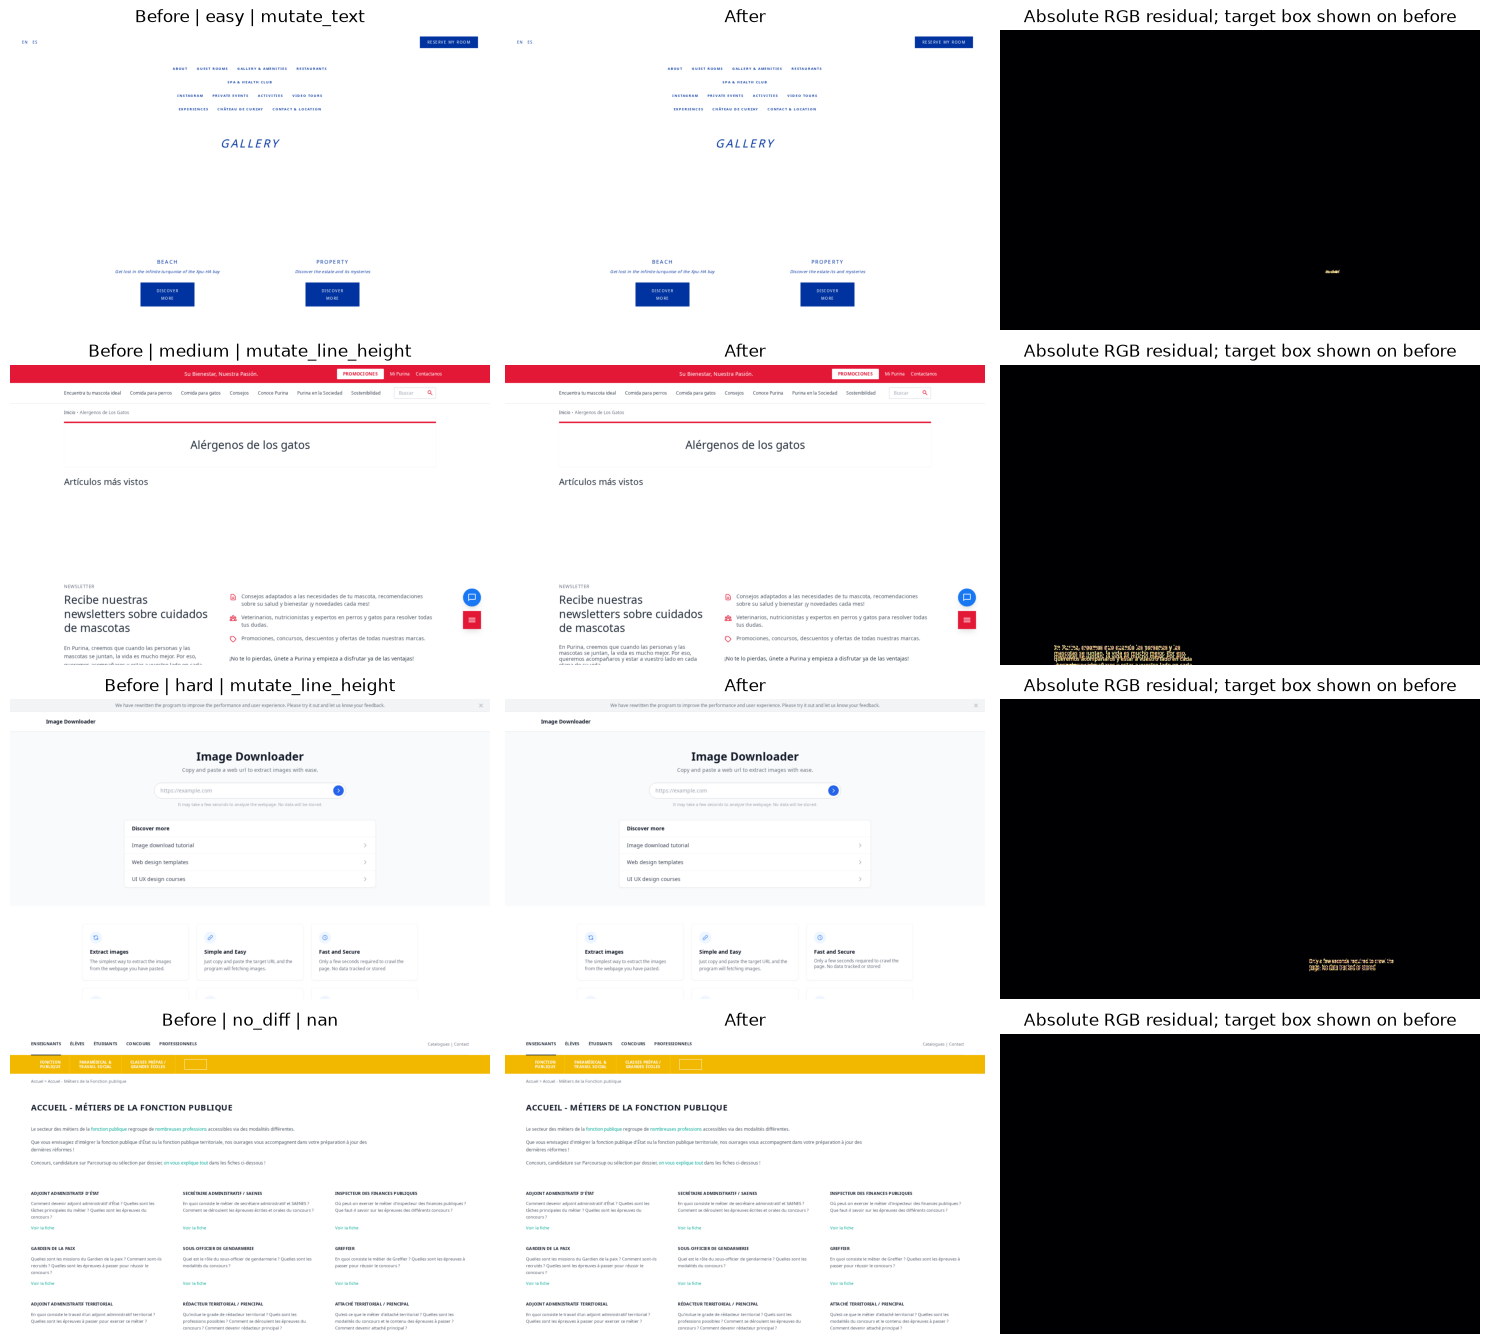

In [3]:
from idu.diffspot import _rgb, residual_map, target_box

example_rows = pd.concat([
    manifest[(manifest.task_type == "visual_diff") & (manifest.difficulty == d)].head(1)
    for d in ("easy", "medium", "hard")
] + [manifest[manifest.task_type == "no_diff"].head(1)], ignore_index=True)
fig, axes = plt.subplots(len(example_rows), 3, figsize=(15, 3.4 * len(example_rows)))
for axrow, (_, row) in zip(axes, example_rows.iterrows()):
    a = _rgb(DATA_ROOT / row.before_path); b = _rgb(DATA_ROOT / row.after_path)
    d = residual_map(a, b)
    gt = target_box(row)
    overlay = a.copy()
    if gt:
        x1,y1,x2,y2 = gt
        cv2.rectangle(overlay,(x1,y1),(x2,y2),(255,30,30),2)
    axrow[0].imshow(a); axrow[0].set_title(f"Before | {row.difficulty} | {row.mutation_types or row.task_type}")
    axrow[1].imshow(b); axrow[1].set_title("After")
    axrow[2].imshow(d, cmap="inferno", vmin=0, vmax=64); axrow[2].set_title("Absolute RGB residual; target box shown on before")
    for ax in axrow: ax.axis("off")
fig.tight_layout()
fig.savefig(REPORT_ROOT / "benchmark_examples.png", dpi=130, bbox_inches="tight")
plt.show()


## 3. Calibrate on calibration rows only

The threshold search uses fixed candidates from 1 through 32 RGB levels. The pair decision is a non-empty residual (minimum one pixel); the highest threshold attaining the best calibration pair F1 is selected to suppress low-amplitude noise. No holdout labels are used.


In [4]:
from idu.diffspot import THRESHOLDS, select_threshold

calibrated_threshold, threshold_table = select_threshold(manifest, THRESHOLDS, min_pixels=1, progress=True)
threshold_table.to_csv(REPORT_ROOT / "threshold_calibration.csv", index=False)
print(f"Calibration-selected RGB threshold: {calibrated_threshold}; minimum residual pixels: 1")
display(threshold_table)


Threshold calibration: 100/880


Threshold calibration: 200/880


Threshold calibration: 300/880


Threshold calibration: 400/880


Threshold calibration: 500/880


Threshold calibration: 600/880


Threshold calibration: 700/880


Threshold calibration: 800/880


Calibration-selected RGB threshold: 16; minimum residual pixels: 1


,threshold,min_changed_pixels,pair_f1,pair_tp,pair_fp,pair_fn,pair_tn
5,16,1,1.000000,780,0,0,100
4,12,1,1.000000,780,0,0,100
3,8,1,1.000000,780,0,0,100
2,4,1,1.000000,780,0,0,100
1,2,1,1.000000,780,0,0,100
0,1,1,1.000000,780,0,0,100
6,24,1,0.994845,772,0,8,100
7,32,1,0.981723,752,0,28,100


## 4. Calibrate the conservative review gate

Choose the most permissive 8×8 grid-coverage threshold that yields zero automatic false-change decisions on synthetic nuisance transforms of calibration no-change pairs. The same threshold must maximize automatic recall on calibration positives under that constraint. The four transforms are generated only from calibration rows; holdout images and labels are not used for gate selection.


In [5]:
from idu.diffspot import calibrate_review_gate

review_grid_threshold, review_gate_table = calibrate_review_gate(
    manifest, calibrated_threshold, progress=True)
review_gate_table.to_csv(REPORT_ROOT / "review_gate_calibration.csv", index=False)
print(f"Calibration-selected max residual grid coverage: {review_grid_threshold:.3f}")
display(review_gate_table)


Review-gate calibration on labeled changes: 200/780


Review-gate calibration on labeled changes: 400/780


Review-gate calibration on labeled changes: 600/780


Calibration-selected max residual grid coverage: 0.075


,max_grid_coverage,calibration_automatic_change_recall,calibration_nuisance_automatic_false_change_rate,calibration_nuisance_review_rate,selected
0,0.025,0.153846,0.0000,1.0000,False
1,0.050,0.500000,0.0000,1.0000,False
2,0.075,0.643590,0.0000,1.0000,True
3,0.100,0.767949,0.0075,0.9925,False
4,0.125,0.878205,0.0075,0.9925,False
5,0.150,0.884615,0.0075,0.9925,False
6,0.175,0.900000,0.0075,0.9925,False
7,0.200,0.920513,0.0075,0.9925,False
8,0.250,0.939744,0.0300,0.9700,False


## 5. End-to-end holdout evaluation

Three methods share the same pair decision rule and target-box evaluator: legacy-style grayscale/Otsu, fixed max-channel RGB residual at 8, and the calibration-selected max-channel RGB residual. The holdout includes changed and no-change controls. A calibrated residual with diffuse/globally explained evidence is `needs_review`; raw candidate detection and automatic change claims are reported separately. Progress is printed every 100 pairs.


In [6]:
from idu.diffspot import evaluate_methods, stratified_summary

started = time.perf_counter()
per_pair, metrics = evaluate_methods(manifest, calibrated_threshold,
                                     fixed_threshold=8, min_changed_pixels=1,
                                     review_grid_threshold=review_grid_threshold, progress=True)
elapsed_s = time.perf_counter() - started
by_difficulty = stratified_summary(per_pair)
per_pair.to_csv(REPORT_ROOT / "holdout_per_pair.csv", index=False)
metrics.to_csv(REPORT_ROOT / "holdout_metrics.csv", index=False)
by_difficulty.to_csv(REPORT_ROOT / "holdout_by_difficulty.csv", index=False)
print(f"Holdout run elapsed: {elapsed_s:.1f}s; evaluated rows: {per_pair.row_idx.nunique()}")
display(metrics)


Holdout evaluation: 100/3520 pairs


Holdout evaluation: 200/3520 pairs


Holdout evaluation: 300/3520 pairs


Holdout evaluation: 400/3520 pairs


Holdout evaluation: 500/3520 pairs


...

Holdout evaluation: 3300/3520 pairs


Holdout evaluation: 3400/3520 pairs


Holdout evaluation: 3500/3520 pairs


Holdout run elapsed: 185.8s; evaluated rows: 3520


,method,pairs,errors,pair_tp,pair_fp,pair_fn,pair_tn,pair_precision,pair_recall,pair_f1,...,automatic_change_precision,automatic_change_recall,automatic_change_f1,automatic_false_positive_rate_no_change,review_rate,automatic_decision_coverage,mean_target_box_iou,median_target_box_iou,target_box_center_hit_rate,residual_inside_target_fraction
0,unregistered_grayscale_otsu,3520,0,3120,0,0,400,1.0,1.0,1.0,...,1.0,0.650000,0.787879,0.0,0.310227,0.689773,0.212577,0.071386,0.998077,0.993271
1,fixed_rgb_residual,3520,0,3120,0,0,400,1.0,1.0,1.0,...,1.0,0.636859,0.778148,0.0,0.321875,0.678125,0.225772,0.076975,0.996795,0.989868
2,calibrated_rgb_residual,3520,0,3120,0,0,400,1.0,1.0,1.0,...,1.0,0.642308,0.782201,0.0,0.317045,0.682955,0.220510,0.075044,0.997756,0.992865


## 6. Difficulty and edit-type breakdown

Averages are reported per difficulty tier and mutation operator because a single aggregate can hide missed, low-pixel edits. `mean_target_box_iou` compares the residual extent box with the benchmark element box; `residual_inside_target_fraction` checks if predicted residual pixels stay within that element. Neither is a segmentation metric.


In [7]:
display(by_difficulty)
mutation_rows = []
for (method, mutation), group in per_pair.groupby(["method", "mutation_types"], dropna=False, sort=True):
    if mutation in ("", "nan"): continue
    r = group.to_dict("records")
    from idu.diffspot import _pair_stats
    mutation_rows.append({"method": method, "mutation_types": mutation, **_pair_stats(r)})
by_mutation = pd.DataFrame(mutation_rows)
by_mutation.to_csv(REPORT_ROOT / "holdout_by_mutation.csv", index=False)
display(by_mutation.sort_values(["method", "pair_f1", "pairs"], ascending=[True, True, False]))


,method,difficulty,pairs,errors,pair_tp,pair_fp,pair_fn,pair_tn,pair_precision,pair_recall,...,automatic_change_precision,automatic_change_recall,automatic_change_f1,automatic_false_positive_rate_no_change,review_rate,automatic_decision_coverage,mean_target_box_iou,median_target_box_iou,target_box_center_hit_rate,residual_inside_target_fraction
0,unregistered_grayscale_otsu,easy,1040,0,1040,0,0,0,1.0,1.0,...,1.0,0.623077,0.767773,NaN,0.376923,0.623077,0.222616,0.076823,0.999038,0.994503
1,fixed_rgb_residual,easy,1040,0,1040,0,0,0,1.0,1.0,...,1.0,0.608654,0.756724,NaN,0.391346,0.608654,0.238654,0.082227,0.996154,0.988577
2,calibrated_rgb_residual,easy,1040,0,1040,0,0,0,1.0,1.0,...,1.0,0.614423,0.761167,NaN,0.385577,0.614423,0.232857,0.080945,0.998077,0.993707
3,unregistered_grayscale_otsu,hard,1040,0,1040,0,0,0,1.0,1.0,...,1.0,0.664423,0.798382,NaN,0.335577,0.664423,0.203697,0.066725,0.999038,0.994184
4,fixed_rgb_residual,hard,1040,0,1040,0,0,0,1.0,1.0,...,1.0,0.650962,0.788585,NaN,0.349038,0.650962,0.213606,0.075592,0.999038,0.992830
5,calibrated_rgb_residual,hard,1040,0,1040,0,0,0,1.0,1.0,...,1.0,0.654808,0.791400,NaN,0.345192,0.654808,0.209523,0.070652,0.999038,0.994286
6,unregistered_grayscale_otsu,medium,1040,0,1040,0,0,0,1.0,1.0,...,1.0,0.662500,0.796992,NaN,0.337500,0.662500,0.211418,0.066970,0.996154,0.991128
7,fixed_rgb_residual,medium,1040,0,1040,0,0,0,1.0,1.0,...,1.0,0.650962,0.788585,NaN,0.349038,0.650962,0.225056,0.072957,0.995192,0.988199
8,calibrated_rgb_residual,medium,1040,0,1040,0,0,0,1.0,1.0,...,1.0,0.657692,0.793503,NaN,0.342308,0.657692,0.219149,0.070686,0.996154,0.990600
9,unregistered_grayscale_otsu,no_diff,400,0,0,0,0,400,NaN,NaN,...,NaN,NaN,NaN,0.0,0.000000,1.000000,NaN,NaN,NaN,NaN


,method,mutation_types,pairs,errors,pair_tp,pair_fp,pair_fn,pair_tn,pair_precision,pair_recall,...,automatic_change_precision,automatic_change_recall,automatic_change_f1,automatic_false_positive_rate_no_change,review_rate,automatic_decision_coverage,mean_target_box_iou,median_target_box_iou,target_box_center_hit_rate,residual_inside_target_fraction
9,calibrated_rgb_residual,mutate_position,253,0,253,0,0,0,1.0,1.0,...,1.0,1.000000,1.000000,NaN,0.000000,1.000000,0.019702,0.012656,1.000000,0.988459
7,calibrated_rgb_residual,mutate_line_height,252,0,252,0,0,0,1.0,1.0,...,1.0,0.373016,0.543353,NaN,0.626984,0.373016,0.283362,0.211887,0.996032,0.988201
8,calibrated_rgb_residual,mutate_opacity,249,0,249,0,0,0,1.0,1.0,...,1.0,0.634538,0.776413,NaN,0.365462,0.634538,0.257590,0.118622,1.000000,0.999676
3,calibrated_rgb_residual,mutate_font_weight,247,0,247,0,0,0,1.0,1.0,...,1.0,0.838057,0.911894,NaN,0.161943,0.838057,0.130901,0.040425,1.000000,0.999149
5,calibrated_rgb_residual,mutate_justify,244,0,244,0,0,0,1.0,1.0,...,1.0,0.229508,0.373333,NaN,0.770492,0.229508,0.305785,0.275221,1.000000,0.999851
0,calibrated_rgb_residual,mutate_border,243,0,243,0,0,0,1.0,1.0,...,1.0,0.444444,0.615385,NaN,0.555556,0.444444,0.247498,0.030303,0.987654,0.964630
4,calibrated_rgb_residual,mutate_gradient,240,0,240,0,0,0,1.0,1.0,...,1.0,0.287500,0.446602,NaN,0.712500,0.287500,0.676859,1.000000,1.000000,0.997382
11,calibrated_rgb_residual,mutate_spacing,240,0,240,0,0,0,1.0,1.0,...,1.0,0.537500,0.699187,NaN,0.462500,0.537500,0.174208,0.084102,1.000000,0.995958
12,calibrated_rgb_residual,mutate_text,236,0,236,0,0,0,1.0,1.0,...,1.0,0.966102,0.982759,NaN,0.033898,0.966102,0.039823,0.010119,0.987288,0.987288
1,calibrated_rgb_residual,mutate_color,233,0,233,0,0,0,1.0,1.0,...,1.0,0.819742,0.900943,NaN,0.180258,0.819742,0.152476,0.037488,1.000000,0.999873


## 7. Test Qwen3-VL only as a crop-level explanation checker

A fixed, balanced 40-pair holdout sample (10 per change difficulty and 10 no-change controls) tests whether Qwen3-VL crop reinspection adds useful changed/no-change evidence. For changed pairs, the crop is selected by the calibrated pixel residual; the model does not choose coordinates or masks. For no-change controls it sees the full same-size pair. We report only its changed/no-change decisions and abstentions; semantic description quality is retained for review but is not assigned an automatic text-similarity score.


In [8]:
import torch
from idu.semantic import HFVLMAdapter
from idu.diffspot import bbox_from_mask, threshold_mask

positive_sample = []
for difficulty in ("easy", "medium", "hard"):
    g = manifest[(manifest.split == "holdout") & (manifest.task_type == "visual_diff") &
                 (manifest.difficulty == difficulty)].sample(n=10, random_state=2026)
    positive_sample.append(g)
negative_sample = [manifest[(manifest.split == "holdout") & (manifest.task_type == "no_diff")]
                   .sample(n=10, random_state=2026)]
vlm_sample = pd.concat(positive_sample + negative_sample, ignore_index=True)

vlm = HFVLMAdapter("Qwen/Qwen3-VL-4B-Instruct", "cuda", use_4bit=False,
                   max_pixels=1024*1024, bbox_format="rel1000", max_new_tokens=256)
vlm_env = vlm.check_environment()
if not vlm_env.get("ok") or not torch.cuda.is_available():
    raise RuntimeError(f"Qwen3-VL diagnostic requires the configured GPU runtime: {vlm_env}")
vlm.load_model()
vlm_rows = []
for n, row in enumerate(vlm_sample.itertuples(index=False), 1):
    a = _rgb(DATA_ROOT / row.before_path); b = _rgb(DATA_ROOT / row.after_path)
    if row.changed:
        delta = residual_map(a, b)
        box = bbox_from_mask(threshold_mask(delta, calibrated_threshold))
    else:
        box = None
    if box:
        x1,y1,x2,y2 = box
        pad = 24
        crop_a = a[max(0,y1-pad):min(a.shape[0],y2+pad), max(0,x1-pad):min(a.shape[1],x2+pad)]
        crop_b = b[max(0,y1-pad):min(b.shape[0],y2+pad), max(0,x1-pad):min(b.shape[1],x2+pad)]
    else:
        crop_a, crop_b = a, b
    verdict = vlm.reinspect(crop_a, crop_b)
    vlm_rows.append({"id": row.id, "difficulty": row.difficulty, "mutation_types": row.mutation_types,
                     "gt_changed": bool(row.changed), "pixel_bbox": box,
                     "vlm_changed": verdict.get("changed", "uncertain"),
                     "vlm_change_type": verdict.get("change_type", ""),
                     "vlm_object": verdict.get("object", ""),
                     "vlm_before": verdict.get("before", ""), "vlm_after": verdict.get("after", ""),
                     "vlm_nuisance": verdict.get("nuisance", ""),
                     "vlm_explanation": verdict.get("explanation", ""),
                     "vlm_raw": verdict.get("raw", "")})
    if n % 5 == 0: print(f"Qwen3-VL crop checks: {n}/{len(vlm_sample)}", flush=True)
del vlm
torch.cuda.empty_cache()
vlm_results = pd.DataFrame(vlm_rows)
vlm_results.to_csv(REPORT_ROOT / "qwen3vl_crop_diagnostic.csv", index=False)
tp = int(((vlm_results.gt_changed) & (vlm_results.vlm_changed == "yes")).sum())
fp = int(((~vlm_results.gt_changed) & (vlm_results.vlm_changed == "yes")).sum())
fn = int(((vlm_results.gt_changed) & (vlm_results.vlm_changed != "yes")).sum())
tn = int(((~vlm_results.gt_changed) & (vlm_results.vlm_changed == "no")).sum())
div = lambda a,b: a/b if b else None
vlm_metrics = {
    "pairs": len(vlm_results), "tp": tp, "fp": fp, "fn": fn, "tn": tn,
    "precision": div(tp,tp+fp), "recall": div(tp,tp+fn),
    "f1": div(2*tp,2*tp+fp+fn), "no_change_specificity": div(tn,tn+fp),
    "uncertain_rate": float((vlm_results.vlm_changed == "uncertain").mean()),
}
(REPORT_ROOT / "qwen3vl_crop_metrics.json").write_text(json.dumps(vlm_metrics, indent=2))
print(vlm_metrics)
display(vlm_results[["id", "gt_changed", "vlm_changed", "vlm_change_type", "vlm_nuisance", "vlm_explanation"]])


`torch_dtype` is deprecated! Use `dtype` instead!


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Qwen3-VL crop checks: 5/40


Qwen3-VL crop checks: 10/40


...

Qwen3-VL crop checks: 30/40


Qwen3-VL crop checks: 35/40


Qwen3-VL crop checks: 40/40


{'pairs': 40, 'tp': 5, 'fp': 0, 'fn': 25, 'tn': 10, 'precision': 1.0, 'recall': 0.16666666666666666, 'f1': 0.2857142857142857, 'no_change_specificity': 1.0, 'uncertain_rate': 0.0}


,id,gt_changed,vlm_changed,vlm_change_type,vlm_nuisance,vlm_explanation
0,fc37b93c-80cd-4d90-96a5-5879434a4022,True,no,none,none,The text content and the underline beneath 'So...
1,741dd284-106e-4507-8b78-910e9a71c7df,True,no,color_change,lighting,The text 'Privacy Terms' appears identical in ...
2,73cb937d-bebd-4c9e-aadc-49b5f72a1fa9,True,yes,text_change,none,The text in the 'before' image shows two separ...
3,d3e5c1ab-d043-40c6-bb68-2667be9a0482,True,no,color_change,lighting,"The text content is identical in both images, ..."
4,5234c2fd-01d7-49bc-8ff9-069c2945f05d,True,no,none,none,The button in both images is identical in cont...
5,a65eb4ec-830a-46ac-87c1-3f7fcd610e5e,True,no,none,none,"The text content, font, spacing, and structure..."
6,a9b97f0a-08ef-4860-89dd-c6350da877f0,True,no,none,none,The text content is identical in both images. ...
7,59c8f661-d1f8-4a6a-a4f6-3bf5bf5221df,True,yes,shape_or_structure_change,none,The primary difference between the two images ...
8,a7b99f2e-9096-4f7d-9dd0-80376bca4e40,True,no,none,none,"The two images are identical in content, inclu..."
9,979cc625-6aaf-445e-8d1c-23de380ffc36,True,no,none,none,"The two images are identical in content, inclu..."


## 8. Nuisance stress test and abstention

The official DiffSpot controls are exact duplicates and do not cover capture nuisances. To check the review policy, 100 held-out no-change screenshots are transformed with global brightness, a broad local shadow, a two-pixel translation, and JPEG quality-70 recompression. These derived cases are **synthetic stress tests**, not additional benchmark examples. The pipeline preserves a residual candidate but emits `needs_review` when the calibrated residual grid coverage exceeds the calibration-selected limit or when global exposure fit / phase correlation flags a likely capture change. This conservative gate trades automatic coverage for safer abstention.


In [9]:
from idu.diffspot import nuisance_stress

stress_pairs, stress_summary = nuisance_stress(manifest, calibrated_threshold, n_controls=100,
                                               review_grid_threshold=review_grid_threshold)
stress_pairs.to_csv(REPORT_ROOT / "nuisance_stress_per_pair.csv", index=False)
stress_summary.to_csv(REPORT_ROOT / "nuisance_stress_metrics.csv", index=False)
display(stress_summary)


,nuisance,pairs,raw_candidate_rate,automatic_false_change_rate,review_rate,mean_grid_coverage,median_candidate_pixels
0,global_brightness,100,1.0,0.00,1.00,0.738906,192026.0
1,local_shadow,100,1.0,0.00,1.00,0.624219,420009.5
2,two_pixel_translation,100,1.0,0.00,1.00,0.655469,49286.5
3,jpeg_recompression_q70,100,1.0,0.01,0.99,0.561094,21125.0


## 9. Inspect model choices against measured evidence

The existing full system’s historical remote-sensing scores are shown as a diagnosis, not as a direct benchmark comparison: those are pixel-mask metrics on LEVIR/SYSU; DiffSpot provides target boxes and no segmentation masks. The decisions here separate localization from semantic explanation and protect against unsupported claims.


In [10]:
prior = pd.read_csv(ROOT / "reports" / "real_dataset_evaluation" / "metrics_by_dataset.csv")
display(prior[["dataset", "variant", "pairs", "precision", "recall", "f1", "iou", "mean_latency_s"]])

component_decisions = pd.DataFrame([
    {"component": "same-viewport residual", "role": "keep", "evidence": "native pixel changes retain subtle CSS edits"},
    {"component": "threshold + residual extent", "role": "keep", "evidence": "localization is derived from observed changed pixels"},
    {"component": "geometric matcher / warp", "role": "exclude here", "evidence": "all benchmark pairs share a 1280x800 canvas; warp can suppress tiny edits"},
    {"component": "DINOv2", "role": "exclude here", "evidence": "semantic invariance is counter to pixel-level fine-grained detection"},
    {"component": "AnyChange / SAM", "role": "exclude here", "evidence": "remote-sensing change domain mismatch"},
    {"component": "Qwen3-VL as mask generator", "role": "exclude", "evidence": "free-form localization must not override pixel evidence; published DiffSpot results show low recall"},
    {"component": "Qwen3-VL crop reinspection", "role": "conditional explanation check", "evidence": "pixel-selected crop; measured separately for yes/no and abstention; never writes a mask"},
    {"component": "OCR", "role": "conditional explanation stage", "evidence": "use only for text-region reading after visual localization"},
], columns=["component", "role", "evidence"])
component_decisions.to_csv(REPORT_ROOT / "component_decisions.csv", index=False)
display(component_decisions)


,dataset,variant,pairs,precision,recall,f1,iou,mean_latency_s
0,ericyu/LEVIRCD_Cropped_256,naive_unregistered_rgb_otsu,5,0.311910,0.467944,0.374318,0.230253,NaN
1,ericyu/SYSU_CD,naive_unregistered_rgb_otsu,5,0.446535,0.372336,0.406074,0.254763,NaN
2,ericyu/LEVIRCD_Cropped_256,evidence_grounded_full_multimodal,5,0.137271,0.089016,0.107998,0.057081,108.657436
3,ericyu/SYSU_CD,evidence_grounded_full_multimodal,5,0.330693,0.180581,0.233600,0.132247,68.792633
4,ericyu/LEVIRCD_Cropped_256,evidence_no_registration,5,0.125080,0.068972,0.088914,0.046525,88.396436
5,ericyu/SYSU_CD,evidence_no_registration,5,0.371529,0.198970,0.259153,0.148866,85.325984
6,ericyu/LEVIRCD_Cropped_256,evidence_classical_only,5,0.103828,0.019944,0.033460,0.017015,1.635495
7,ericyu/SYSU_CD,evidence_classical_only,5,0.533928,0.144696,0.227688,0.128469,1.715866


,component,role,evidence
0,same-viewport residual,keep,native pixel changes retain subtle CSS edits
1,threshold + residual extent,keep,localization is derived from observed changed ...
2,geometric matcher / warp,exclude here,all benchmark pairs share a 1280x800 canvas; w...
3,DINOv2,exclude here,semantic invariance is counter to pixel-level ...
4,AnyChange / SAM,exclude here,remote-sensing change domain mismatch
5,Qwen3-VL as mask generator,exclude,free-form localization must not override pixel...
6,Qwen3-VL crop reinspection,conditional explanation check,pixel-selected crop; measured separately for y...
7,OCR,conditional explanation stage,use only for text-region reading after visual ...


## 10. Qualitative holdout review

The saved cases include subtle edits, a hard-tier pair, and a no-change control. The residual extent is outlined in green; the supplied target element is outlined in red. The report does not convert the residual into an unsupported semantic caption.


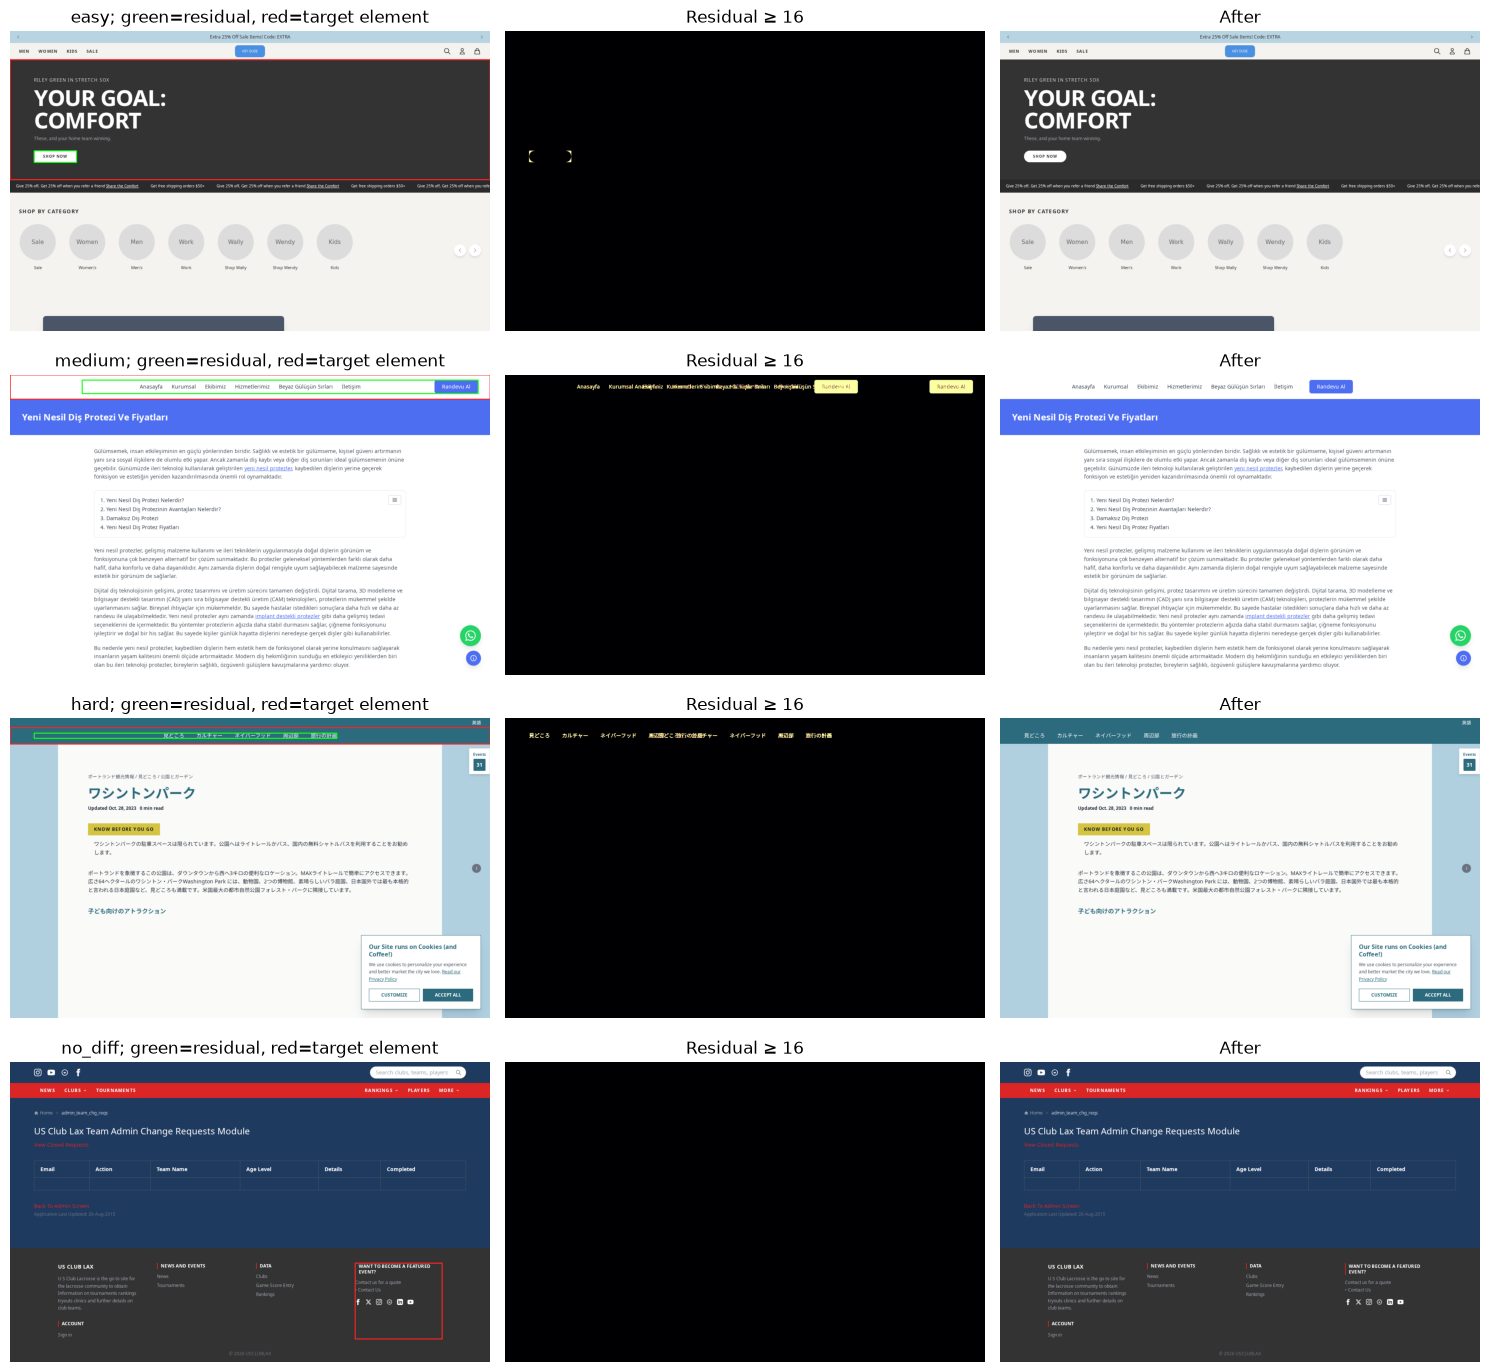

In [11]:
from idu.diffspot import bbox_from_mask, threshold_mask

qual_ids = []
for difficulty in ("easy", "medium", "hard"):
    candidates = manifest[(manifest.split == "holdout") & (manifest.task_type == "visual_diff") &
                          (manifest.difficulty == difficulty)].sort_values("id")
    qual_ids.append(candidates.iloc[0])
qual_ids.append(manifest[(manifest.split == "holdout") & (manifest.task_type == "no_diff")].sort_values("id").iloc[0])
fig, axes = plt.subplots(len(qual_ids), 3, figsize=(15, 3.5 * len(qual_ids)))
for j, (axrow, row) in enumerate(zip(axes, qual_ids)):
    a = _rgb(DATA_ROOT / row.before_path); b = _rgb(DATA_ROOT / row.after_path)
    delta = residual_map(a, b); pred_box = bbox_from_mask(threshold_mask(delta, calibrated_threshold))
    target = target_box(row); overlay = a.copy()
    if target:
        cv2.rectangle(overlay, (target[0],target[1]), (target[2],target[3]), (255,35,35), 2)
    if pred_box:
        cv2.rectangle(overlay, (pred_box[0],pred_box[1]), (pred_box[2],pred_box[3]), (20,255,20), 2)
    axrow[0].imshow(overlay)
    axrow[0].set_title(f"{row.difficulty}; green=residual, red=target element")
    axrow[1].imshow(delta, cmap="inferno", vmin=0, vmax=64)
    axrow[1].set_title(f"Residual ≥ {calibrated_threshold}")
    axrow[2].imshow(b)
    axrow[2].set_title("After")
    for ax in axrow: ax.axis("off")
fig.tight_layout()
fig.savefig(REPORT_ROOT / "qualitative_holdout.png", dpi=130, bbox_inches="tight")
plt.show()


## 11. Persisted conclusions and limitations

The notebook writes a concise report and all compact metric tables under `reports/fine_grained_upgrade/`. The actual executed notebook carries its cell outputs and per-stage progress.


In [12]:
calib_rows = int((manifest.split == "calibration").sum())
holdout_rows = int((manifest.split == "holdout").sum())
best = metrics.loc[metrics.method == "calibrated_rgb_residual"].iloc[0]
vlm_meta = json.loads((REPORT_ROOT / "qwen3vl_crop_metrics.json").read_text())
stress_lines = "\n".join(
    f"- {r.nuisance}: raw residual candidate rate {r.raw_candidate_rate:.3f}; "
    f"automatic false-change rate {r.automatic_false_change_rate:.3f}; review rate {r.review_rate:.3f}"
    for r in stress_summary.itertuples(index=False))
report = f'''# Fine-grained upgrade evaluation report

**Dataset:** Tencent DiffSpot, complete test split ({len(manifest):,} screenshot pairs; MIT per dataset card).
**Split:** deterministic stratification by task/difficulty; {calib_rows:,} calibration, {holdout_rows:,} holdout.
**Threshold:** {calibrated_threshold} max-channel RGB levels, selected using calibration pair F1 only.
**Review gate:** {review_grid_threshold:.3f} maximum 8×8 residual-grid coverage, selected on calibration positives subject to zero automatic false changes on calibration nuisance transforms.
**Holdout runtime:** {elapsed_s:.1f} seconds.

## Calibrated residual method

- Pair precision: {best.pair_precision:.4f}
- Pair recall: {best.pair_recall:.4f}
- Pair F1: {best.pair_f1:.4f}
- No-change false-positive rate: {best.no_change_false_positive_rate:.4f}
- Automatic change precision after review gate: {best.automatic_change_precision:.4f}
- Automatic change recall after review gate: {best.automatic_change_recall:.4f}
- Automatic change F1 after review gate: {best.automatic_change_f1:.4f}
- Holdout review rate: {best.review_rate:.4f}
- Mean target-box IoU of residual extent: {best.mean_target_box_iou:.4f}
- Target-box center hit rate: {best.target_box_center_hit_rate:.4f}
- Fraction of residual pixels inside the labeled target element: {best.residual_inside_target_fraction:.4f}

Qwen3-VL crop-reinspection diagnostic ({vlm_meta['pairs']} balanced holdout pairs): F1 {vlm_meta['f1']:.3f}, precision {vlm_meta['precision']:.3f}, recall {vlm_meta['recall']:.3f}, no-change specificity {vlm_meta['no_change_specificity']:.3f}, uncertain rate {vlm_meta['uncertain_rate']:.3f}. This small model diagnostic is separate from the detector; it does not establish semantic caption accuracy.

These are pair-detection and element-box grounding metrics. The benchmark does not provide pixel masks; pixel F1, pixel IoU, Dice, pixel accuracy, OCR CER, semantic type accuracy, calibration ECE, and claim hallucination rates are therefore not reported here. Residual containment is a benchmark grounding check, not pixel-mask precision against an annotated change mask.

Pair F1 counts a detected residual candidate, including candidates held for review. Automatic precision/recall/F1 count only `localized_change` decisions. This separates finding a visual discrepancy from asserting that it is a meaningful change.

## Nuisance stress (derived controls)

{stress_lines}

Diffuse residuals are marked `needs_review` rather than automatically asserted as changes. These transforms are synthetic stress checks on real no-change screenshots and do not substitute for naturally captured nuisance pairs.

## Interpretation

This benchmark’s controlled same-viewport setup favors direct pixel evidence. Registration and semantic-embedding models are excluded from the detector because their invariances can discard fine CSS/text edits. Any semantic captioning should be a separate optional stage grounded in the proposed region and verified against visual evidence. This focused result should not be generalized to natural scenes, product photography, physical defects, documents, or remote-sensing images.

## Artifacts

- `holdout_metrics.csv`, `holdout_by_difficulty.csv`, `holdout_by_mutation.csv`
- `review_gate_calibration.csv`
- `qwen3vl_crop_metrics.json`, `qwen3vl_crop_diagnostic.csv`
- `nuisance_stress_metrics.csv`, `nuisance_stress_per_pair.csv`
- `holdout_per_pair.csv`, `threshold_calibration.csv`, `split_counts.csv`
- `benchmark_examples.png`, `qualitative_holdout.png`, `environment.json`
'''
(REPORT_ROOT / "README.md").write_text(report)
print(report)


# Fine-grained upgrade evaluation report

**Dataset:** Tencent DiffSpot, complete test split (4,400 screenshot pairs; MIT per dataset card).
**Split:** deterministic stratification by task/difficulty; 880 calibration, 3,520 holdout.
**Threshold:** 16 max-channel RGB levels, selected using calibration pair F1 only.
**Review gate:** 0.075 maximum 8×8 residual-grid coverage, selected on calibration positives subject to zero automatic false changes on calibration nuisance transforms.
**Holdout runtime:** 185.8 seconds.

## Calibrated residual method

- Pair precision: 1.0000
- Pair recall: 1.0000
- Pair F1: 1.0000
- No-change false-positive rate: 0.0000
- Automatic change precision after review gate: 1.0000
- Automatic change recall after review gate: 0.6423
- Automatic change F1 after review gate: 0.7822
- Holdout review rate: 0.3170
- Mean target-box IoU of residual extent: 0.2205
- Target-box center hit rate: 0.9978
- Fraction of residual pixels inside the labeled target element: 0.9929